<a href="https://colab.research.google.com/github/gauigbeui/AI-Electronic-and-Computer-Dept/blob/main/LIM%20ARTYOM%20E40A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- X (Feature data :: Matrix(2D array):16x2 ---
[[55 30]
 [57 31]
 [64 36]
 [63 30]
 [58 33]
 [49 25]
 [54 37]
 [61 34]
 [56 52]
 [47 52]
 [56 50]
 [46 53]
 [49 50]
 [53 53]
 [52 49]
 [48 54]]

--- y (label data :: 1D Array(Vector)) ---
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1]

New data: length=59, height=35
Predicted class: 0 (Dachshund)
Probability -> Dachshund: 0.995, Jindo: 0.005


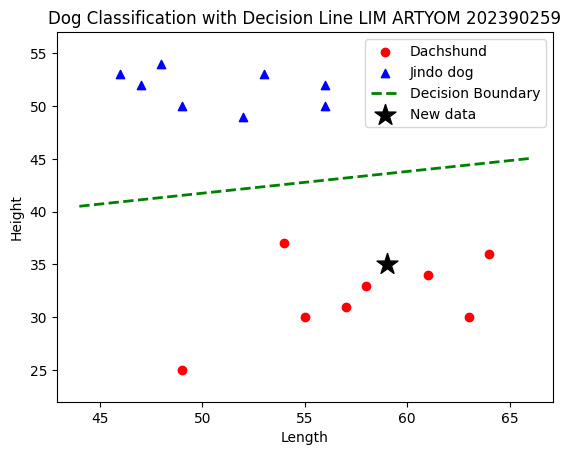

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression


dach_length = [55, 57, 64, 63, 58, 49, 54, 61]
dach_height = [30, 31, 36, 30, 33, 25, 37, 34]


jin_length = [56, 47, 56, 46, 49, 53, 52, 48]
jin_height = [52, 52, 50, 53, 50, 53, 49, 54]


X = np.array(
    [[l, h] for l, h in zip(dach_length + jin_length,
                          dach_height + jin_height)]
)
y = np.array([0] * len(dach_length) + [1] * len(jin_length))


print("--- X (Feature data :: Matrix(2D array):16x2 ---")
print(X)

print("\n--- y (label data :: 1D Array(Vector)) ---")
print(y)


model = LogisticRegression()
model.fit(X, y)


plt.scatter(dach_length, dach_height, c='r', label='Dachshund')
plt.scatter(jin_length, jin_height, c='b', marker='^', label='Jindo dog')


x_values = np.linspace(min(X[:, 0]) - 2, max(X[:, 0]) + 2, 200)


w1 = model.coef_[0][0]
w2 = model.coef_[0][1]
b = model.intercept_[0]

y_values = -(w1 * x_values + b) / w2

plt.plot(x_values, y_values, 'g--', linewidth=2, label='Decision Boundary')


newdata_length = [59]
newdata_height = [35]

new_X = np.array([[newdata_length[0], newdata_height[0]]])

pred = model.predict(new_X)[0]
proba = model.predict_proba(new_X)[0]

names = {0: 'Dachshund', 1: 'Jindo dog'}
print(f"\nNew data: length={newdata_length[0]}, height={newdata_height[0]}")
print(f"Predicted class: {pred} ({names[pred]})")
print(f"Probability -> Dachshund: {proba[0]:.3f}, Jindo: {proba[1]:.3f}")


plt.scatter(newdata_length, newdata_height, c='k', marker='*', s=250, label='New data')


plt.ylim(min(X[:, 1]) - 3, max(X[:, 1]) + 3)

plt.xlabel('Length')
plt.ylabel('Height')
plt.title("Dog Classification with Decision Line LIM ARTYOM 202390259")

plt.legend(loc='upper right')

plt.show()